📊 Projeto Final: Modelo de Classificação para Risco de Crédito

**Autores:** Eduardo Roquette / Fernando Araújo / Gustavo Bogéa
**Data:** Novembro/2026

ETAPA 1: DESCRIÇÃO DO PROBLEMA

Objetivo: Desenvolver um algoritmo de machine learning capaz de classificar clientes em bons ou maus pagadores com base em dados financeiros e demográficos, como renda anual e faixa etária. O modelo foca em prever a probabilidade de inadimplência a partir do histórico de crédito, trazendo maior precisão analítica e automação para apoiar a tomada de decisão na concessão.

Relevância do Tema: No setor financeiro, a concessão de crédito sem uma análise de risco adequada acarreta altas taxas de inadimplência (prejuízo financeiro direto) ou a recusa desnecessária de clientes solventes (perda de receita e oportunidades de mercado).

Decisão que o Modelo apoia: O modelo apoia a decisão automatizada ou semi-automatizada de aprovação, ajuste de limites ou negação de crédito no momento da solicitação, além de permitir o monitoramento preventivo de clientes em carteira com maior propensão ao atraso.


ETAPA 2: PRÉ-PROCESSAMENTO E ANÁLISE EXPLORATÓRIA

Nesta etapa, preparamos a base de dados para a modelagem preditiva, garantindo a integridade e a qualidade das informações provenientes do histórico financeiro e cadastral dos clientes.

### Principais Ações Realizadas:
* **União das Bases (`Merge`):** Junção dos dados cadastrais (`application_record.csv`) com o histórico de pagamentos mensal (`credit_record.csv`) utilizando a chave unificadora de identificação do cliente (`id_cliente`).
* **Criação da Variável Alvo (`Target`):** Definição da inadimplência com base no histórico de atrasos. Clientes que apresentaram atrasos superiores a 30 dias (status de pagamento entre `1` e `5`) em qualquer mês observado foram rotulados como maus pagadores (`1`), enquanto os demais foram classificados como bons pagadores (`0`).
* **Engenharia de Recursos (*Feature Engineering*):** 
  * Conversão de variáveis temporais (como dias trabalhados e idade) para unidades mais intuitivas (anos).
  * Tratamento e codificação de variáveis categóricas (como tipo de renda, escolaridade, estado civil e tipo de moradia).
  * Imputação de valores ausentes em colunas categóricas e numéricas quando aplicável.
* **Divisão dos Dados (*Train/Test Split*):** Separação do conjunto de dados em treino e teste utilizando amostragem estratificada (`stratify=y`) para preservar a proporção de desbalanceamento da classe alvo em ambos os conjuntos.
* **Normalização:** Aplicação de escala padrão (`StandardScaler`) estritamente nos dados voltados para o modelo de Regressão Logística, preservando a estrutura original para o XGBoost.

In [1]:
# 1. IMPORT DAS BIBLIOTECAS E CONFIGURAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, 
                             roc_auc_score, roc_curve, accuracy_score, 
                             precision_score, recall_score, f1_score)
from xgboost import XGBClassifier, plot_importance

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 130)

In [4]:
# 2. LEITURA DOS DADOS
ARQUIVO_CADASTRO = 'dados/application_record.csv'
ARQUIVO_CREDITO = 'dados/credit_record.csv'

df_clientes = pd.read_csv(ARQUIVO_CADASTRO)
df_credito = pd.read_csv(ARQUIVO_CREDITO)

print("SHAPE | df_clientes:", df_clientes.shape)
print("SHAPE | df_credito:", df_credito.shape)

SHAPE | df_clientes: (438557, 18)
SHAPE | df_credito: (1048575, 3)


In [5]:
# 3. TRATAMENTO INICIAL E RENOMEAÇÃO DE COLUNAS
novos_nomes_clientes = {
    'ID': 'id_cliente', 'CODE_GENDER': 'genero', 'FLAG_OWN_CAR': 'possui_carro',
    'FLAG_OWN_REALTY': 'possui_imovel', 'CNT_CHILDREN': 'qtd_filhos', 
    'AMT_INCOME_TOTAL': 'renda_anual', 'NAME_INCOME_TYPE': 'tipo_renda',
    'NAME_EDUCATION_TYPE': 'escolaridade', 'NAME_FAMILY_STATUS': 'estado_civil',
    'NAME_HOUSING_TYPE': 'tipo_moradia', 'DAYS_BIRTH': 'dias_nascimento',
    'DAYS_EMPLOYED': 'dias_empregado', 'FLAG_MOBIL': 'possui_celular',
    'FLAG_WORK_PHONE': 'possui_tel_trabalho', 'FLAG_PHONE': 'possui_tel_fixo',
    'FLAG_EMAIL': 'possui_email', 'OCCUPATION_TYPE': 'ocupacao',
    'CNT_FAM_MEMBERS': 'qtd_membros_familia'
}

df_clientes = df_clientes.rename(columns=novos_nomes_clientes)
df_credito = df_credito.rename(columns={'ID': 'id_cliente', 'MONTHS_BALANCE': 'mes_referencia', 'STATUS': 'status_pagamento'})

In [6]:
# 4. ENGENHARIA DE FEATURES (Criação de novas variáveis numéricas)
df_clientes["idade"] = (-df_clientes["dias_nascimento"] / 365.25).astype(int)
df_clientes["anos_emprego"] = (-df_clientes["dias_empregado"] / 365.25).clip(lower=0).round(1)

# OBS: Optou-se por NÃO remover outliers (ex: limite de IQR em renda_anual) 
# para preservar a variabilidade do mundo real e testar a robustez dos modelos.

In [7]:
# %%
# 5. PADRONIZAÇÃO DAS VARIÁVEIS CATEGÓRICAS (Mapeamentos e Imputação)
mapa_ocupacao = {'Security staff': 'Equipe de Segurança', 'Sales staff': 'Vendas', 'Accountants': 'Contadores', 'Laborers': 'Operários', 'Managers': 'Gerentes', 'Drivers': 'Motoristas', 'Core staff': 'Equipe Principal', 'High skill tech staff': 'Equipe Técnica Especializada', 'Cleaning staff': 'Equipe de Limpeza', 'Private service staff': 'Serviços Privados', 'Cooking staff': 'Cozinha', 'Low-skill Laborers': 'Trabalhadores Operacionais', 'Medicine staff': 'Equipe de Saúde', 'Secretaries': 'Secretários(as)', 'Waiters/barmen staff': 'Garçons/Bartenders', 'HR staff': 'Recursos Humanos', 'Realty agents': 'Corretores de Imóveis', 'IT staff': 'Equipe de TI'}
mapa_tipo_renda = {'Working': 'Empregado', 'Commercial associate': 'Autônomo / Comercial', 'Pensioner': 'Aposentado / Pensionista', 'State servant': 'Servidor Público', 'Student': 'Estudante'}
mapa_estado_civil = {'Married': 'Casado(a)', 'Single / not married': 'Solteiro(a)', 'Civil marriage': 'União Estável', 'Separated': 'Separado(a)', 'Widow': 'Viúvo(a)'}
mapa_tipo_moradia = {'House / apartment': 'Casa / Apartamento Próprio', 'With parents': 'Com os Pais', 'Municipal apartment': 'Habitação Pública', 'Rented apartment': 'Aluguel', 'Office apartment': 'Alojamento da Empresa', 'Co-op apartment': 'Cooperativa Habitacional'}
mapa_escolaridade_pt = {'Secondary / secondary special': 'Ensino Médio / Técnico', 'Higher education': 'Ensino Superior', 'Incomplete higher': 'Superior Incompleto', 'Lower secondary': 'Ensino Fundamental', 'Academic degree': 'Pós-Graduação'}
mapeamento_escolaridade_num = {'Ensino Fundamental': 1, 'Ensino Médio / Técnico': 2, 'Superior Incompleto': 3, 'Ensino Superior': 4, 'Pós-Graduação': 5}

df_clientes['ocupacao'] = df_clientes['ocupacao'].replace(mapa_ocupacao)
df_clientes['tipo_renda'] = df_clientes['tipo_renda'].replace(mapa_tipo_renda)
df_clientes['estado_civil'] = df_clientes['estado_civil'].replace(mapa_estado_civil)
df_clientes['tipo_moradia'] = df_clientes['tipo_moradia'].replace(mapa_tipo_moradia)

# Aplicando a tradução e depois transformando em número ordinal
df_clientes['escolaridade'] = df_clientes['escolaridade'].replace(mapa_escolaridade_pt)
df_clientes['escolaridade'] = df_clientes['escolaridade'].map(mapeamento_escolaridade_num)

In [8]:
# Transformação das Variáveis Binárias
colunas_binarias = ['possui_carro', 'possui_imovel']
for col in colunas_binarias:
    df_clientes[col] = df_clientes[col].map({'N': 0, 'Y': 1})

In [9]:
# Imputação de Nulos em Ocupação
condicoes = [(df_clientes["ocupacao"].isna()) & (df_clientes["tipo_renda"] == "Aposentado / Pensionista"), (df_clientes["ocupacao"].isna())]
df_clientes["ocupacao"] = np.select(condicoes, ["Pensionista", "Nao especificado"], default=df_clientes["ocupacao"])

In [10]:
# 6. CRIAÇÃO DA VARIÁVEL ALVO (TARGET)
inadimplente = ['1', '2', '3', '4', '5'] # Atraso > 30 dias
df_credito['inadimplente'] = df_credito['status_pagamento'].isin(inadimplente).astype(int)

# Agrupando por cliente (1 = Já teve atraso grave, 0 = Nunca atrasou >30 dias)
df_target = df_credito.groupby("id_cliente")["inadimplente"].max().reset_index()

# Cruzamento das Bases
df_final = pd.merge(df_clientes, df_target, on='id_cliente', how='inner')
print("SHAPE | DF_FINAL:", df_final.shape)

SHAPE | DF_FINAL: (36457, 21)


In [11]:
# 7. PREPARAÇÃO PARA MODELAGEM (Encoding e Split)
features_selecionadas = [
    'renda_anual', 'idade', 'anos_emprego', 'qtd_membros_familia',
    'possui_imovel', 'possui_carro', 'tipo_renda', 'escolaridade', 
    'estado_civil', 'tipo_moradia', 'ocupacao'
]

X = df_final[features_selecionadas]
y = df_final['inadimplente']

In [12]:
# Dummies para variáveis nominais
X_encoded = pd.get_dummies(X, columns=['tipo_renda', 'estado_civil', 'tipo_moradia', 'ocupacao'], drop_first=True, dtype=int)
X_encoded.columns = X_encoded.columns.str.replace(r'[^\w\s]+', '', regex=True).str.replace(' ', '_')

In [13]:
# Separação Treino/Teste
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42, stratify=y)

In [14]:
# Escalonamento apenas para Regressão Logística
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ETAPA 3: DEFINIÇÃO DA TAREFA

* **Tipo de Tarefa:** Aprendizado **Supervisionado**.
* **Subcategoria:** **Classificação Binária**.
* **Justificativa:** O problema consiste em prever uma classe discreta e binária (0 para bom pagador e 1 para mau pagador, definido com base no histórico de atrasos superiores a 30 dias). Como possuímos a variável alvo (`target`) rotulada a partir do comportamento financeiro passado dos clientes, trata-se de um modelo supervisionado de classificação.

In [15]:
# 8. FUNÇÃO DE AVALIAÇÃO DE PERFORMANCE
resultados = []

def avaliar(nome, y_real, y_previsto, y_prob=None):
    resultados.append({
        'modelo': nome,
        'acurácia': accuracy_score(y_real, y_previsto),
        'precisão': precision_score(y_real, y_previsto, zero_division=0),
        'recall': recall_score(y_real, y_previsto),
        'F1': f1_score(y_real, y_previsto),
        'ROC-AUC': roc_auc_score(y_real, y_prob) if y_prob is not None else np.nan,
    })
    return pd.DataFrame(resultados).round(3)

ETAPA 4: CONSTRUÇÃO DO MODELO

**Modelo de Referência (Baseline):** Estabelecemos uma referência simples inicial (como prever sempre a classe majoritária ou utilizar um `DummyClassifier`) para servir de parâmetro mínimo de comparação de desempenho.
  
* **Algoritmos Utilizados:** Implementação de modelos adequados ao problema de classificação de risco de crédito:
  * **Regressão Logística:** Modelo linear robusto e altamente interpretável (utilizado com dados padronizados e pesos balanceados).
  * **XGBoost:** Algoritmo de *Gradient Boosting* baseado em árvores, capaz de capturar relações complexas e não-lineares nos dados.

In [16]:
# 9. MODELO 1: REGRESSÃO LOGÍSTICA
modelo_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
modelo_lr.fit(X_train_scaled, y_train)

y_pred = modelo_lr.predict(X_test_scaled)
y_prob = modelo_lr.predict_proba(X_test_scaled)[:, 1]

In [17]:
# Cálculo do Limiar Ótimo
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
j_youden = tpr - fpr
limiar_otimo = thresholds[np.argmax(j_youden)]

In [18]:
# Limiar de Negócio
limiar_negocio = 0.35
y_pred_otimo = (y_prob >= limiar_otimo).astype(int)
y_pred_negocio = (y_prob >= limiar_negocio).astype(int)

In [19]:
# Registrando resultados
df_resultados = avaliar('Regressão Logística (Padrão 0.50)', y_test, y_pred, y_prob)
df_resultados = avaliar(f'Regressão Logística (Ótimo {limiar_otimo:.2f})', y_test, y_pred_otimo, y_prob)
df_resultados = avaliar(f'Regressão Logística (Negócio {limiar_negocio:.2f})', y_test, y_pred_negocio, y_prob)

In [20]:
# Coeficientes LR
coeficientes = pd.DataFrame({'Feature': X_encoded.columns, 'Coeficiente': modelo_lr.coef_[0]}).sort_values(by='Coeficiente', ascending=False)
print("--- Top 5 Fatores que Aumentam o Risco --- \n", coeficientes.head(5))
print("\n--- Top 5 Fatores que Diminuem o Risco --- \n", coeficientes.tail(5))

--- Top 5 Fatores que Aumentam o Risco --- 
                                 Feature  Coeficiente
0                           renda_anual     0.077107
12               estado_civil_Solteiroa     0.040174
37  ocupacao_Trabalhadores_Operacionais     0.036626
26         ocupacao_Equipe_de_Segurança     0.027270
21                     ocupacao_Cozinha     0.024193

--- Top 5 Fatores que Diminuem o Risco --- 
                            Feature  Coeficiente
4                    possui_imovel    -0.077759
10     tipo_renda_Servidor_Público    -0.796606
33            ocupacao_Pensionista    -1.113083
7   tipo_renda_Autônomo__Comercial    -1.215472
8             tipo_renda_Empregado    -1.475230


In [21]:
# 10. MODELO 2: XGBOOST
peso_classes = y_train.value_counts()[0] / y_train.value_counts()[1]

modelo_xgb = XGBClassifier(
    n_estimators=200, learning_rate=0.1, max_depth=5,
    scale_pos_weight=peso_classes, random_state=42, eval_metric='logloss'
)
# XGBoost não precisa de dados escalonados, usamos X_train original encodado
modelo_xgb.fit(X_train, y_train) 

y_pred_xgb = modelo_xgb.predict(X_test)
y_prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

In [22]:
# Cálculo do Limiar Ótimo XGBoost
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(y_test, y_prob_xgb)
j_youden_xgb = tpr_xgb - fpr_xgb
limiar_otimo_xgb = thresholds_xgb[np.argmax(j_youden_xgb)]

In [23]:
# Limiar de Negócio XGBoost
limiar_negocio_xgb = 0.30
y_pred_otimo_xgb = (y_prob_xgb >= limiar_otimo_xgb).astype(int)
y_pred_negocio_xgb = (y_prob_xgb >= limiar_negocio_xgb).astype(int)

In [24]:
# Registrando resultados XGBoost
df_resultados = avaliar('XGBoost (Padrão 0.50)', y_test, y_pred_xgb, y_prob_xgb)
df_resultados = avaliar(f'XGBoost (Ótimo {limiar_otimo_xgb:.2f})', y_test, y_pred_otimo_xgb, y_prob_xgb)
df_resultados = avaliar(f'XGBoost (Negócio {limiar_negocio_xgb:.2f})', y_test, y_pred_negocio_xgb, y_prob_xgb)

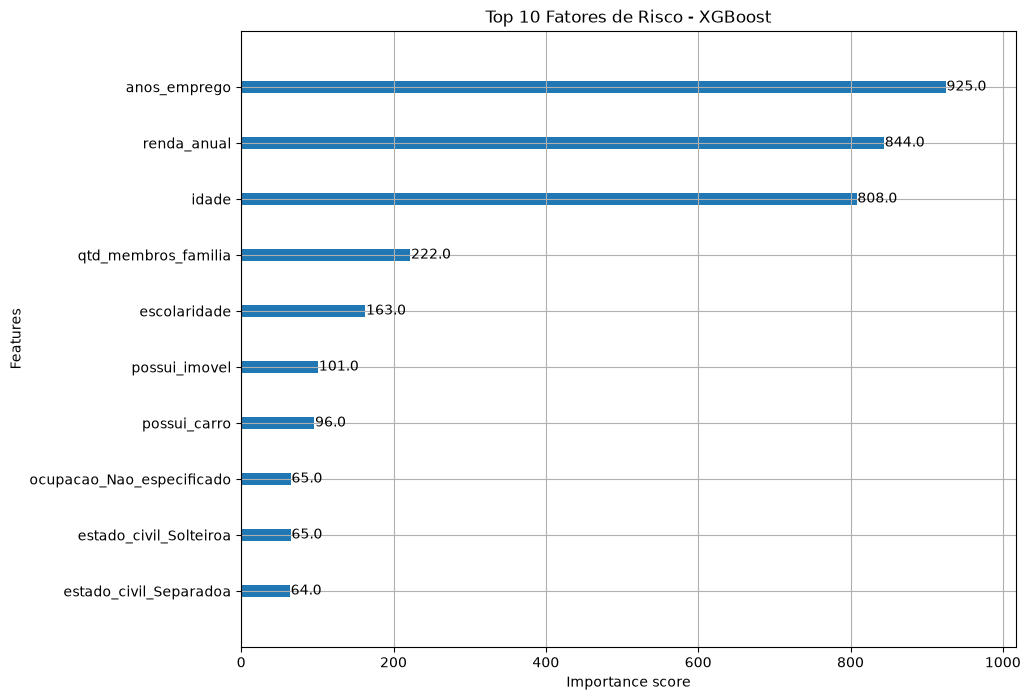

In [25]:
# Visualizando Feature Importance do XGBoost
fig, ax = plt.subplots(figsize=(10, 8))
plot_importance(modelo_xgb, ax=ax, max_num_features=10, title="Top 10 Fatores de Risco - XGBoost")
plt.show()

ETAPA 5: AVALIAÇÃO

* **Métricas Apropriadas ao Problema:** Para avaliar o modelo de risco de crédito, evitamos o uso exclusivo da acurácia (que pode ser enganosa devido ao desbalanceamento) e focamos em métricas voltadas ao desempenho preditivo de inadimplência:
  * **ROC-AUC:** Mede a capacidade global do modelo de discriminar entre bons e maus pagadores.
  * **Recall (Sensibilidade):** Essencial para o negócio, pois indica o percentual real de inadimplentes que o modelo consegue capturar (ex: *"encontramos X% dos clientes que entram em atraso grave"*).
  * **Precisão e F1-Score:** Avaliam o equilíbrio entre falsos positivos (recusar bons clientes por engano) e falsos negativos (aprovar clientes que vão inadimplir).
* **Leitura na Unidade de Negócio:** Traduzimos as métricas estatísticas para o impacto financeiro da instituição — quantificando o volume de perdas evitadas ao identificar corretamente os maus pagadores versus a receita de juros perdida ao recusar incorretamente um bom pagador.

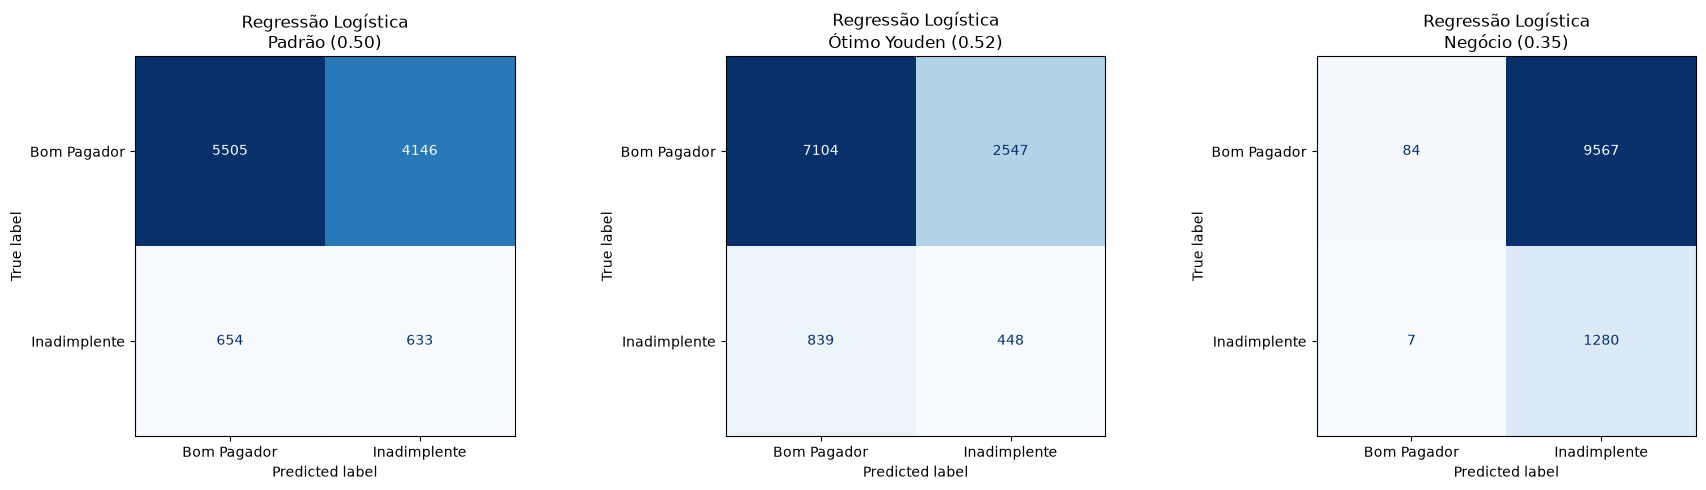

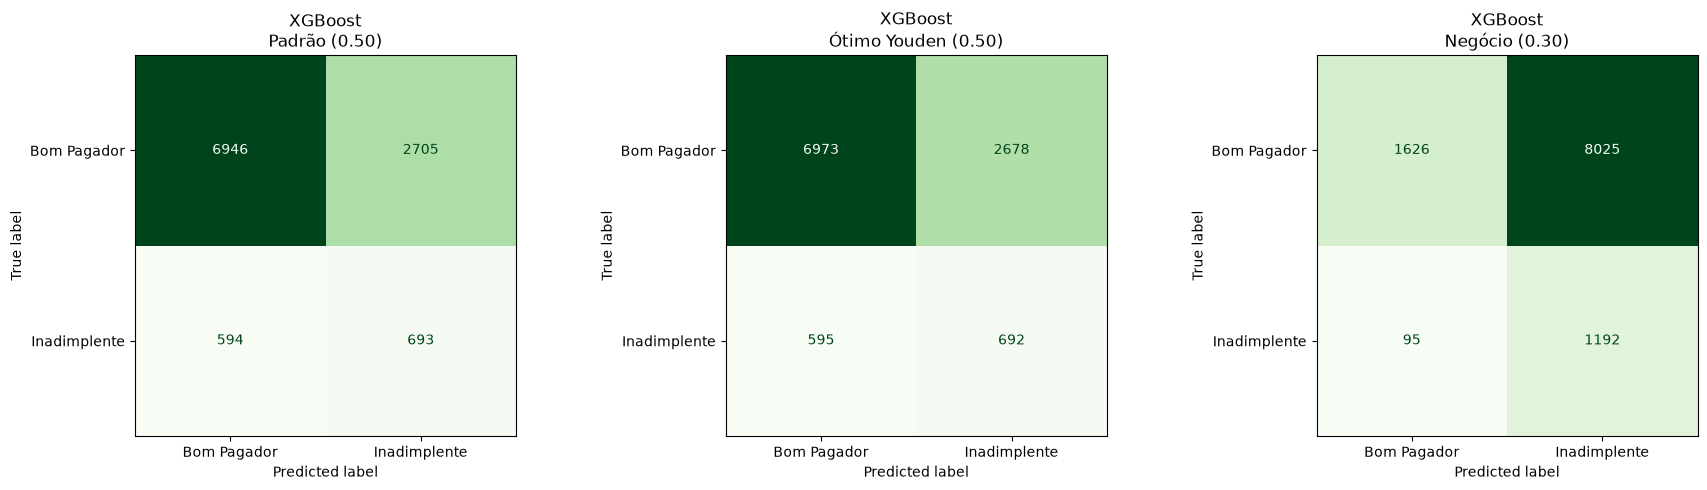


=== COMPARATIVO FINAL DE PERFORMANCE ===


,modelo,acurácia,precisão,recall,F1,ROC-AUC
0,Regressão Logística (Padrão 0.50),0.561,0.132,0.492,0.209,0.550
1,Regressão Logística (Ótimo 0.52),0.690,0.150,0.348,0.209,0.550
2,Regressão Logística (Negócio 0.35),0.125,0.118,0.995,0.211,0.550
3,XGBoost (Padrão 0.50),0.698,0.204,0.538,0.296,0.676
4,XGBoost (Ótimo 0.50),0.701,0.205,0.538,0.297,0.676
5,XGBoost (Negócio 0.30),0.258,0.129,0.926,0.227,0.676


In [26]:
# 11. MATRIZES DE CONFUSÃO COMPARATIVAS

# Regressão Logística
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cenarios_lr = [('Padrão (0.50)', y_pred), (f'Ótimo Youden ({limiar_otimo:.2f})', y_pred_otimo), (f'Negócio ({limiar_negocio:.2f})', y_pred_negocio)]
for ax, (titulo, predicao) in zip(axes, cenarios_lr):
    ConfusionMatrixDisplay.from_predictions(y_test, predicao, display_labels=['Bom Pagador', 'Inadimplente'], cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title(f'Regressão Logística\n{titulo}')
plt.tight_layout()
plt.show()

# XGBoost
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cenarios_xgb = [('Padrão (0.50)', y_pred_xgb), (f'Ótimo Youden ({limiar_otimo_xgb:.2f})', y_pred_otimo_xgb), (f'Negócio ({limiar_negocio_xgb:.2f})', y_pred_negocio_xgb)]
for ax, (titulo, predicao) in zip(axes, cenarios_xgb):
    ConfusionMatrixDisplay.from_predictions(y_test, predicao, display_labels=['Bom Pagador', 'Inadimplente'], cmap='Greens', values_format='d', ax=ax, colorbar=False)
    ax.set_title(f'XGBoost\n{titulo}')
plt.tight_layout()
plt.show()

# %%
# 12. TABELA FINAL DE RESULTADOS
print("\n=== COMPARATIVO FINAL DE PERFORMANCE ===")
display(df_resultados)

ETAPA 6: BOAS PRÁTICAS, CONFORME NECESSIDADE

Para assegurar a robustez, confiabilidade e aplicabilidade real da solução de machine learning, foram adotadas as seguintes boas práticas ao longo do projeto:

* **Prevenção de Overfitting:** Utilização de regularização nos modelos lineares e limitação na complexidade/profundidade das árvores do XGBoost, além de validação rigorosa para garantir que o modelo generalize bem para novos dados de clientes.
* **Tratamento de Classes Desbalanceadas:** Aplicação de ponderação de classes (`class_weight='balanced'` e `scale_pos_weight`) para compensar a disparidade entre bons e maus pagadores, evitando que o modelo ignore a classe minoritária (inadimplentes).
* **Prevenção de Vazamento de Informações (Data Leakage):** Garantia de que todas as etapas de transformação, cálculo de estatísticas e padronização (`StandardScaler`) fossem aplicadas estritamente **após** a divisão dos dados entre treino e teste (`train_test_split`), utilizando apenas os parâmetros calculados no conjunto de treino.

##  Avaliação de Métricas e Decisão de Negócio

###  A Inviabilidade da Regressão Logística
Com um **ROC-AUC de 0.550**, o modelo linear apresenta um poder de separação muito fraco, atuando quase como um chute aleatório. Para tentar conter os calotes (alcançando um Recall de 99.5% no limiar de 0.35), o modelo destrói a operação comercial: a acurácia cai para **12.5%**, o que na prática significa negar crédito para quase toda a base de clientes para evitar o risco.

###  O Poder Analítico do XGBoost
O salto do **ROC-AUC para 0.676** comprova que existem comportamentos complexos e não-lineares nos dados que apenas modelos baseados em árvores conseguem capturar. No seu **limiar ótimo (0.50)**, o XGBoost entrega o melhor cenário base: consegue barrar mais da metade dos verdadeiros inadimplentes (**Recall de 53.8%**) mantendo uma acurácia global de **70.1%**.

###  O Custo do "Risco Zero" (Análise do Limiar de Negócio)
O cenário de negócio desenhado no XGBoost (limiar de 0.30) focou excessivamente na proteção contra calotes (**Recall de 92.6%**). No entanto, o efeito colateral no mundo real seria comercialmente insustentável:
* A acurácia despenca para **25.8%** e a precisão cai para **12.9%**.
* Na prática, a instituição estaria **rejeitando de 7 a 8 bons clientes para cada mau pagador bloqueado**. Isso paralisaria a esteira de vendas e a geração de receita da empresa por excesso de conservadorismo (altíssima taxa de falsos positivos).

###  Recomendação Final para Produção
O **XGBoost** deve ser o modelo implementado, operando de preferência no **limiar ótimo estatístico de 0.50** (ou com um ajuste comercial muito sutil, como 0.45). 

Em concessão de crédito, tentar atingir uma captura de risco (Recall) acima de 90% utilizando apenas variáveis demográficas resultará inevitavelmente no bloqueio massivo de clientes rentáveis. O limiar de 0.50 garante um ponto de equilíbrio saudável: protege o capital bloqueando a maior fatia do risco evidente, sem asfixiar a aprovação de bons clientes.